# Strip waveguide bend
This notebook contains code that simulates bend waveguide parameters using **Lumerical MODE**. \
The objective is to obtain loss values across radius sweep.

In [1]:
%%capture
# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

import numpy as np
from collections import OrderedDict
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge, Rectangle
import lumapi
import lumerical_utils as lu

In [2]:
%%html
<style>
  table {margin-left: 0 !important;}
</style>

In [3]:
# Constants
um = 1e-6
nm = 1e-9
c = 2.99792458e8;

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [4]:
# Si/SiO2 220x500nm 1550nm

wavelength_center = 1.55*um
core_thickness = 220*nm
core_width = 500*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

radius_sweep = np.arange(1*um, 20*um, 0.5*um)
core_material = "Si (Silicon) - Palik"
clad_material = "SiO2 (Glass) - Palik"

In [5]:
# Si3N4/SiO2 1000x360nm 1550nm

wavelength_center = 1.55*um
core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

radius_sweep = np.arange(15*um, 60*um, 5*um)
core_material = "Si3N4 (Silicon Nitride) - Luke"
clad_material = "SiO2 (Glass) - Palik"

In [6]:
waveguide_length = 3.14*min(radius_sweep)

# Core
core_rect = {
    "name": "core",
    "x": 0,
    "x span": core_width,
    "y": 0,
    "y span": waveguide_length,
    "z min": 0,
    "z max": core_thickness
}

# Clad
clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_width = core_width + 2*core_width*20
clad_rect = {
    "name": "clad",
    "x": 0,
    "x span": clad_width,
    "y": 0,
    "y span": waveguide_length,
    "z": 0,
    "z span": clad_thickness,
}

# FDE
# Some of those values are only initial aand will be changed later
clad_cells_x = 100
clad_cells_z = 100
clad_dx = clad_width/clad_cells_x
clad_dz = clad_thickness/clad_cells_z
fde_solver = {
    "x": 0,
    "y": 0,
    "z": core_thickness/2,
    "z span": 2*top_clad_thickness - 2*clad_dz,
    "define x mesh by": "maximum mesh step",
    "dx": clad_dx,
    "define z mesh by": "maximum mesh step",
    "dz": clad_dz,

    "pml layers": 12,
    "fit materials with multi-coefficient model": True,
    "x min bc": "PML",
    "x max bc": "PML",
}
fde_solver["x span"] = (clad_cells_x - 2*fde_solver["pml layers"])*clad_dx

# Waveguide preview

Code below creates simplified top-view of the bend waveguide. \
Plot is presented for the maximal radii defined in `radius_sweep`

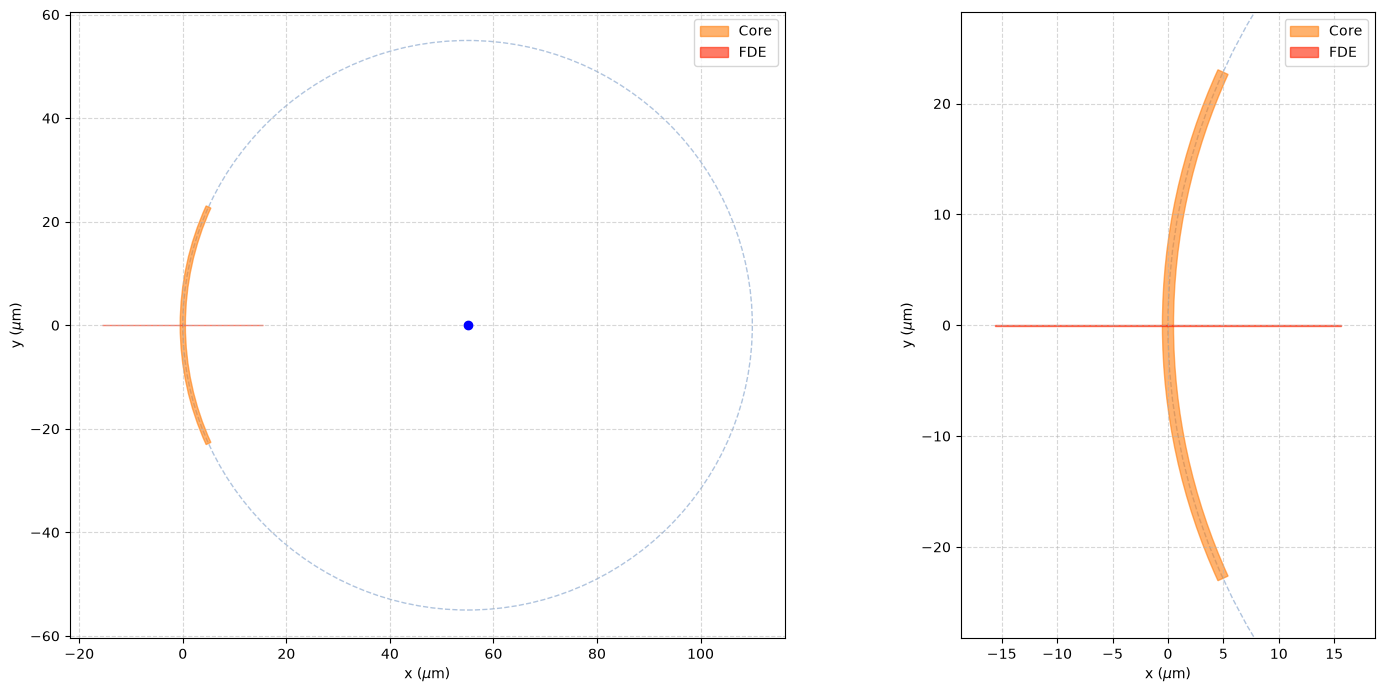

In [7]:
waveguide_length_um = waveguide_length*1e6
core_width_um = core_width*1e6

bend_radius_um = max(radius_sweep)*1e6
bend_center_um = [fde_solver["x"]*1e6 + bend_radius_um, fde_solver["y"]*1e6]

solver_center_um = [fde_solver["x"]*1e6, fde_solver["y"]*1e6]
solver_width_um = fde_solver["x span"]*1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

def draw_waveguide_plot(ax):
    # Bend
    circle = plt.Circle(
        bend_center_um,
        bend_radius_um, 
        color='#b0c4de', 
        fill=False, 
        linestyle='--', 
        linewidth=1,
    )
    ax.add_patch(circle)
    ax.plot(*bend_center_um, 'bo')
    
    arc_angle_deg = (waveguide_length_um/bend_radius_um)*(180/np.pi)
    theta_start = 180.0 - arc_angle_deg/2
    theta_end = 180.0 + arc_angle_deg/2
    
    # Core
    r_outer = bend_radius_um + core_width_um/2
    core_arc = Wedge(
        bend_center_um,
        r_outer,
        theta_start,
        theta_end,
        width=core_width*1e6,
        color='#ff7f0e',
        alpha=0.6,
        label="Core"
    )
    ax.add_patch(core_arc)
    
    solver_center = [solver_center_um[0] - solver_width_um/2, solver_center_um[1] - 0.05/2]
    solver_region = Rectangle(
        solver_center,
        fde_solver["x span"]*1e6,
        0.05,
        color='#FF2400',
        alpha=0.6,
        label="FDE"
    )
    ax.add_patch(solver_region)
    
    
    # --- Formatting ---
    ax.legend(loc="upper right")
    ax.set_aspect('equal')
    ax.set_xlabel(r"x ($\mu\text{m}$)", fontsize=10)
    ax.set_ylabel(r"y ($\mu\text{m}$)", fontsize=10)
    
    ax.grid(True, linestyle="--", alpha=0.5)


draw_waveguide_plot(ax1)

draw_waveguide_plot(ax2)
ax2.set_ylim(0 - (waveguide_length_um)*0.6, 0 + (waveguide_length_um)*0.6)
ax2.set_xlim(0 - solver_width_um*0.6,0 + solver_width_um*0.6)
plt.tight_layout()
plt.show()

In [8]:
# Materials

mode = lumapi.MODE(hide=False)
mode.switchtolayout()

try:
    mode.deletematerial(f"{core_material} Fitted")
except:
    pass

core_material_fitted = mode.copymaterial(core_material)
mode.setmaterial(core_material_fitted, "tolerance", 0.001)
mode.setmaterial(core_material_fitted, "max coefficients", 6)
mode.setmaterial(core_material_fitted, "specify fit range", True)
mode.setmaterial(core_material_fitted, "wavelength min", wavelength_center - 150*nm)
mode.setmaterial(core_material_fitted, "wavelength max", wavelength_center + 150*nm)
mode.setmaterial(core_material_fitted, "name", f"{core_material} Fitted")

try:
    mode.deletematerial(f"{clad_material} Fitted")
except:
    pass

clad_material_fitted = mode.copymaterial(clad_material)
mode.setmaterial(clad_material_fitted, "tolerance", 0.001)
mode.setmaterial(clad_material_fitted, "max coefficients", 6)
mode.setmaterial(clad_material_fitted, "specify fit range", True)
mode.setmaterial(clad_material_fitted, "wavelength min", wavelength_center - 150*nm)
mode.setmaterial(clad_material_fitted, "wavelength max", wavelength_center + 150*nm)
mode.setmaterial(clad_material_fitted, "name", f"{clad_material} Fitted")

In [9]:
# Grid calculation

frequency_center = c/wavelength_center
core_n = np.real(mode.getmodeindex(f"{core_material} Fitted", frequency_center).item());
dmesh = wavelength_center/(30 * core_n)

print(f"For core with n = {core_n:.3f} and wavelength = {wavelength_center*1e6:.2f} um, mesh size: {dmesh*1e9:.2f} nm")

For core with n = 1.996 and wavelength = 1.55 um, mesh size: 25.88 nm


In [10]:
# Clad
mode.addrect(clad_rect)
mode.set("material", f"{clad_material} Fitted")

# Core
mode.addrect(core_rect)
mode.set("material", f"{core_material} Fitted")

# FDE
mode.addfde()
mode.set("solver type", "2D Y Normal")
mode.set(fde_solver)
mode.set("number of trial modes", 4)
mode.set("wavelength", wavelength_center)
mode.set("dx", dmesh)
mode.set("dz", dmesh)

In [ ]:
# Grid optimization

x_min_span = 1.1*mode.getnamed("core", "x span")
z_min_span = 1.1*mode.getnamed("core", "z span")

x_max_span = mode.getnamed("FDE", "x span")
z_max_span = mode.getnamed("FDE", "z span")

lu.optimize_simulation_axis(
    mode,
    axis="z", 
    target_decay=1e-10,
    span_min=z_min_span, 
    span_max=z_max_span,
    max_iterations=15, 
    decades_tolerance=0.2,
    Efield_source="FDE::data::mode1",
    boundry_layers=12,
)

optimal_x_span = lu.optimize_simulation_axis(
    mode,
    axis="x", 
    target_decay=1e-10,
    span_min=x_min_span, 
    span_max=x_max_span,
    max_iterations=15, 
    decades_tolerance=0.2,
    Efield_source="FDE::data::mode1",
    boundry_layers=12,
)

--- Optimizing Z Span (Target Decay: 1.0000e-10) ---
Z Iter 1: z span = 0.396 µm | Decay = 1.0000e+00 (Log: 0.00)
Z Iter 2: z span = 5.094 µm | Decay = 4.2518e-07 (Log: -6.37)
Z Iter 3: z span = 7.444 µm | Decay = 3.0725e-10 (Log: -9.51)
Z Iter 4: z span = 8.618 µm | Decay = 8.3040e-12 (Log: -11.08)
Z Iter 5: z span = 8.031 µm | Decay = 4.9365e-11 (Log: -10.31)
Solver error at z span 7.74 µm: "Can not find object 'FDE::data::mode1'"


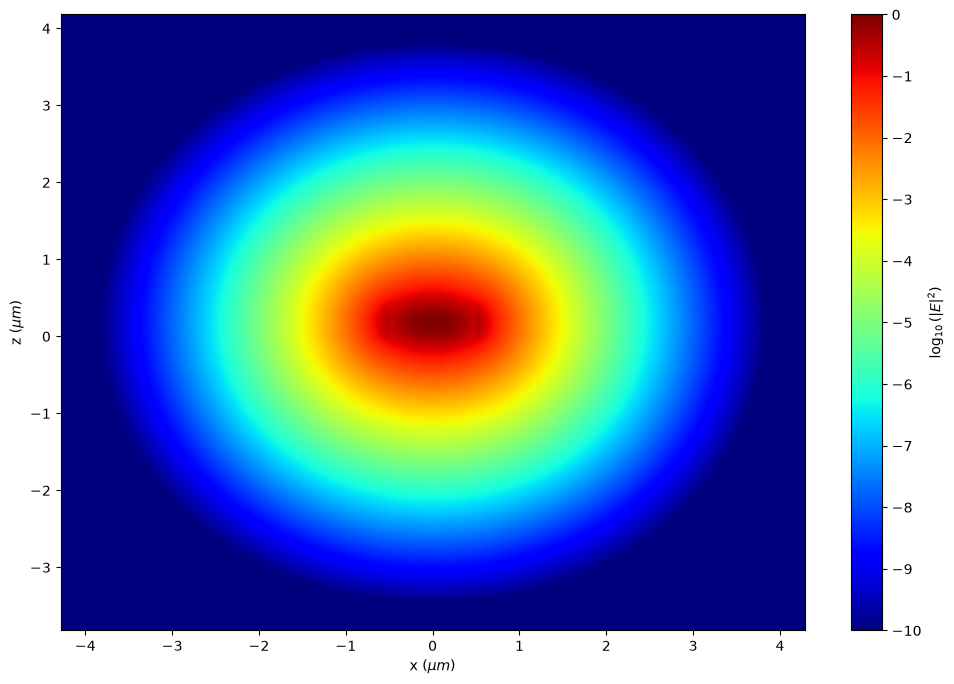

In [12]:
# Find modes for straight waveguide
mode.findmodes()
mode.cleardcard()
modes_count = int(mode.nummodes())
for m in range(1, modes_count+1):
    mode.copydcard(f"FDE::data::mode{m}", f"straight_wg_mode{m}")

Efield = mode.getresult("FDE::data::mode1", "E")
fig, ax  = lu.plot_Efield(Efield)

plt.show()

In [ ]:
# Minimal solver radius

# https://optics.ansys.com/hc/en-us/articles/360034917253-Solving-bent-waveguides-in-FDE-and-FEEM
min_solver_radius = mode.get("x span")/2 + mode.get("dx")*(mode.get("pml layers")+1)
min_radius_sweep = min(radius_sweep)
if min_radius_sweep < min_solver_radius:
    print(f"Warning! Minimum radius ({min_radius_sweep}) can not be smaller than {min_solver_radius}")

radius_sweep = radius_sweep[radius_sweep > min_solver_radius]
print(radius_sweep)

In [ ]:
# Find modes for bent waveguide
mode.switchtolayout()
mode.set("number of trial modes", 10)
mode.set("bent waveguide", True)
mode.set("bend location", "user specified")
mode.set("bend orientation", -90)
mode.set("bend location x", core_rect["x"])
mode.set("bend location y", core_rect["y"])
mode.set("bend location z", core_thickness/2)

radius_data = {
    "radius": [],
    "neff": [],
    "f": [],
    "loss": [],
    "ng": [],
    "TE polarization fraction": [],
    "waveguide TE/TM fraction": [],
    "mode effective area": [],
    "Efield": [],
    "Hfield": [],
    "power coupling": []
}

for r, radius in enumerate(radius_sweep):
    print(f"Calculating for radius: {radius*1e6:.1f}")
    mode.switchtolayout()
    mode.set("bend radius", radius)

    modes_count = mode.findmodes()
    if modes_count < 1:
        continue

    # It still can be numerical artifact here
    # We have to extend one side of solver to confirm
    lu.optimize_simulation_axis(
        mode,
        axis="x", 
        target_decay=1e-10,
        span_min=optimal_x_span, 
        span_max=optimal_x_span*2,
        max_iterations=5, 
        decades_tolerance=0.2,
        Efield_source="FDE::data::mode1",
        boundry_layers=12,
        extend_side="negative",
        strict=False
    )

    modes_count = mode.findmodes()
    # It was numeric artifact, so restore span and start over for new radius
    if modes_count < 1:
        mode.switchtolayout()
        mode.set("x", fde_solver["x"])
        mode.set("x span", optimal_x_span)
        continue

    # radius
    radius_data["radius"].append(radius)

    # neff
    neff = mode.getdata("FDE::data::mode1", "neff").item()
    radius_data["neff"].append(neff)

    # f
    f = mode.getdata("FDE::data::mode1", "f")
    radius_data["f"].append(f)

    # loss
    loss = mode.getdata("FDE::data::mode1", "loss")
    radius_data["loss"].append(loss)

    # ng
    ng = mode.getdata("FDE::data::mode1", "ng").item()
    radius_data["ng"].append(ng)

    # TE polarization fraction (%)
    te_fraction = mode.getdata("FDE::data::mode1", "TE polarization fraction")
    radius_data["TE polarization fraction"].append(te_fraction)

    # waveguide TE/TM fraction (%)
    waveguide_fraction = mode.getdata("FDE::data::mode1", "waveguide TE/TM fraction")
    radius_data["waveguide TE/TM fraction"].append(waveguide_fraction)

    # mode effective area (um^2)
    eff_area = mode.getdata("FDE::data::mode1", "mode effective area")
    radius_data["mode effective area"].append(eff_area)

    # Efield
    Efield = mode.getresult("FDE::data::mode1", "E")
    radius_data["Efield"].append(Efield)

    # Hfield
    Hfield = mode.getresult("FDE::data::mode1", "H")
    radius_data["Hfield"].append(Hfield)

    # Power coupling
    power_coupling = mode.overlap("FDE::data::mode1", "straight_wg_mode1")[1]
    radius_data["power coupling"].append(power_coupling)

    print(f"Radius {radius*1e6:.1f}: {loss} ")

In [ ]:
# core_id = core_material.split()[0]
np.savez("radius_data.npz", **radius_data)

In [213]:
radius_data = np.load("results/si_500nm_220nm.npz")

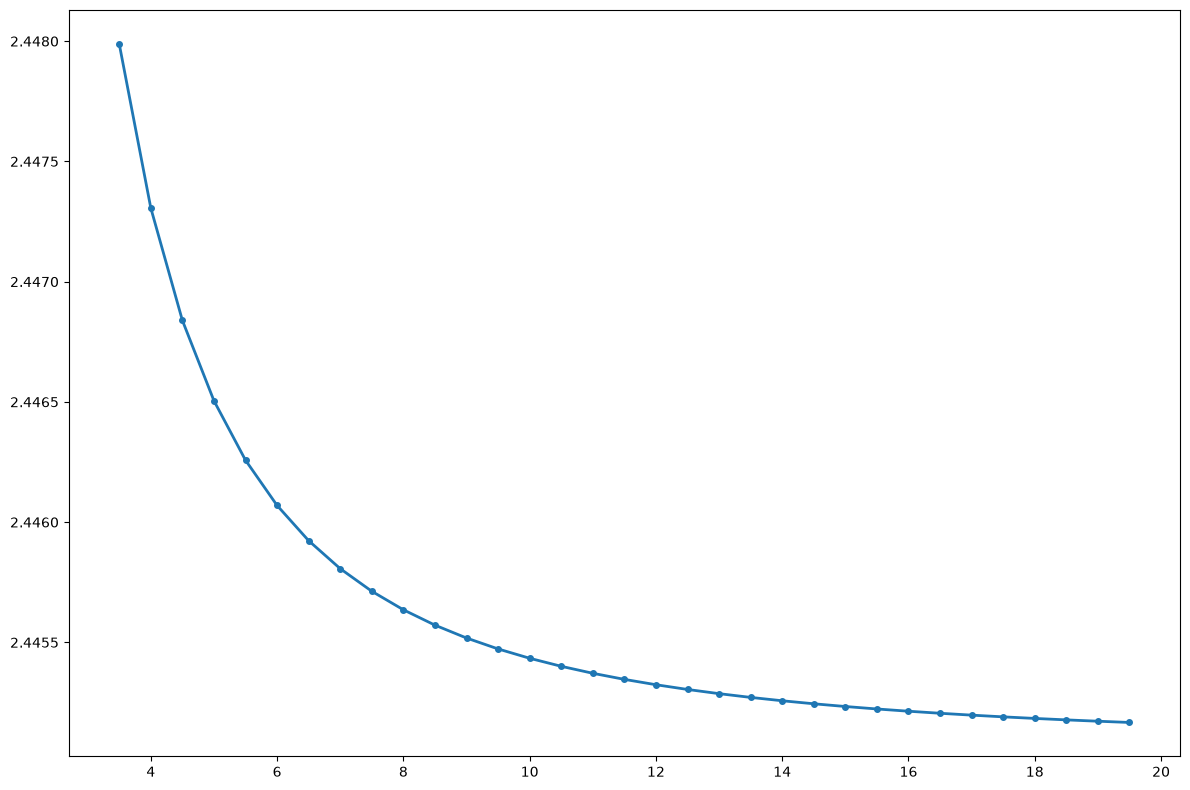

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.plot(
    np.array(radius_data["radius"]) * 1e6,
    np.real(np.array(radius_data["neff"])),
    marker="o",
    markersize=4,
    linestyle="-",
    linewidth=2,
)


plt.tight_layout()
plt.show()

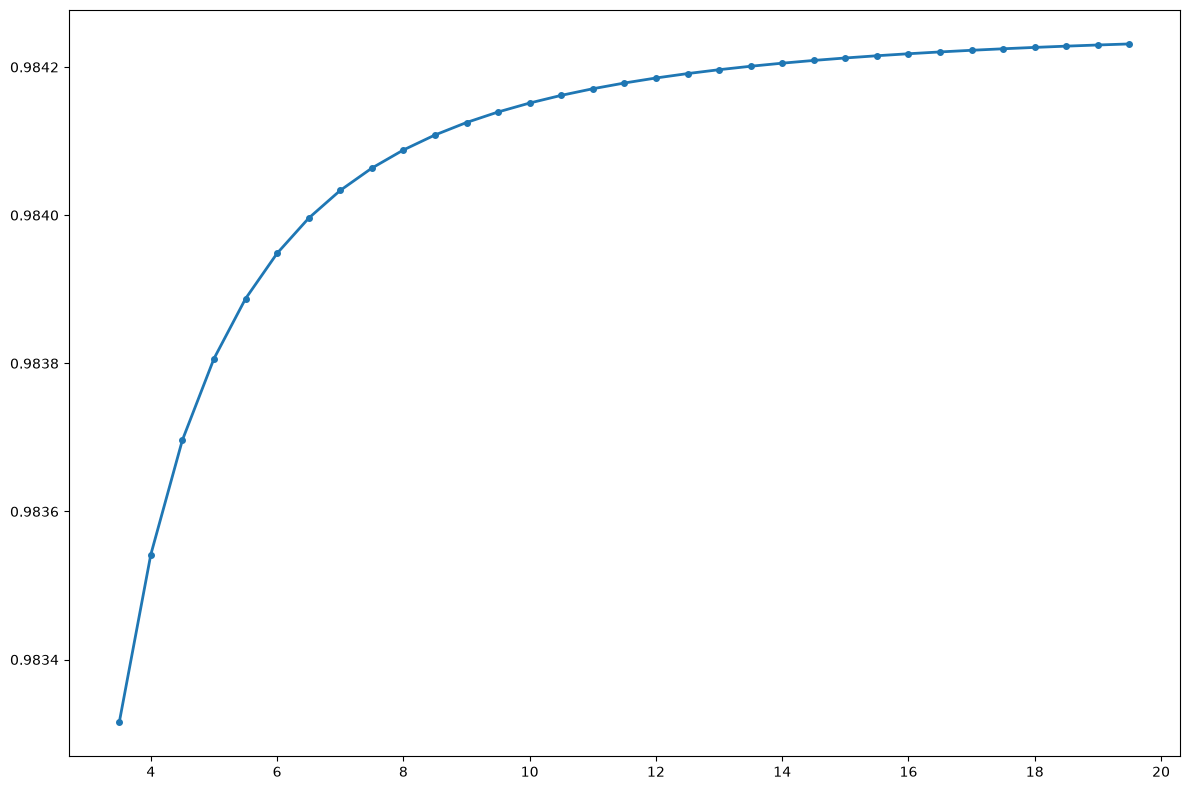

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.plot(
    np.array(radius_data["radius"]) * 1e6,
    np.array(radius_data["TE polarization fraction"]),
    marker="o",
    markersize=4,
    linestyle="-",
    linewidth=2,
)


plt.tight_layout()
plt.show()

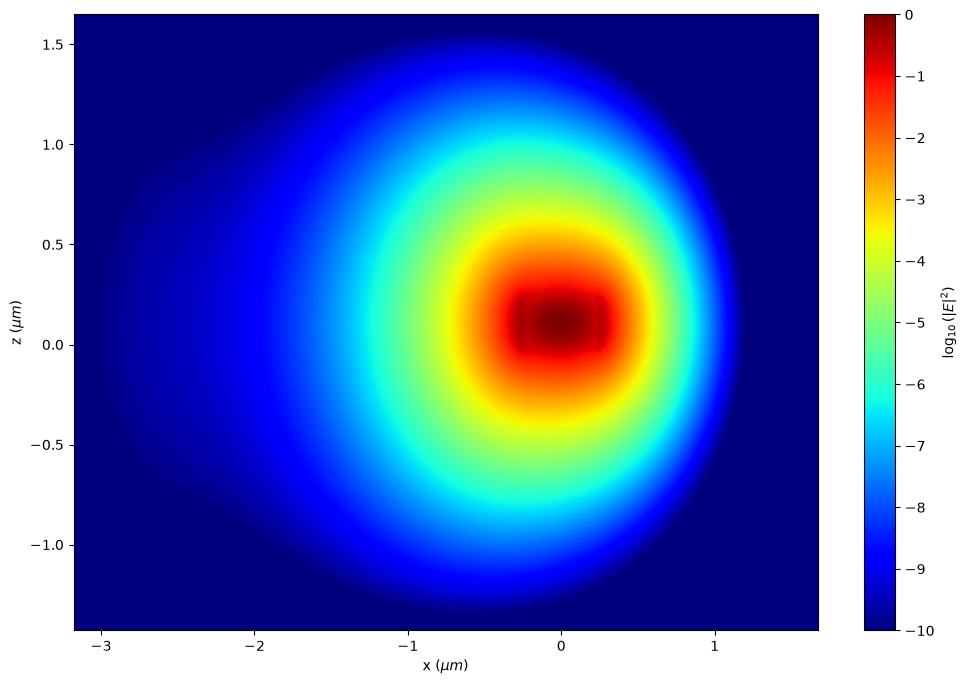

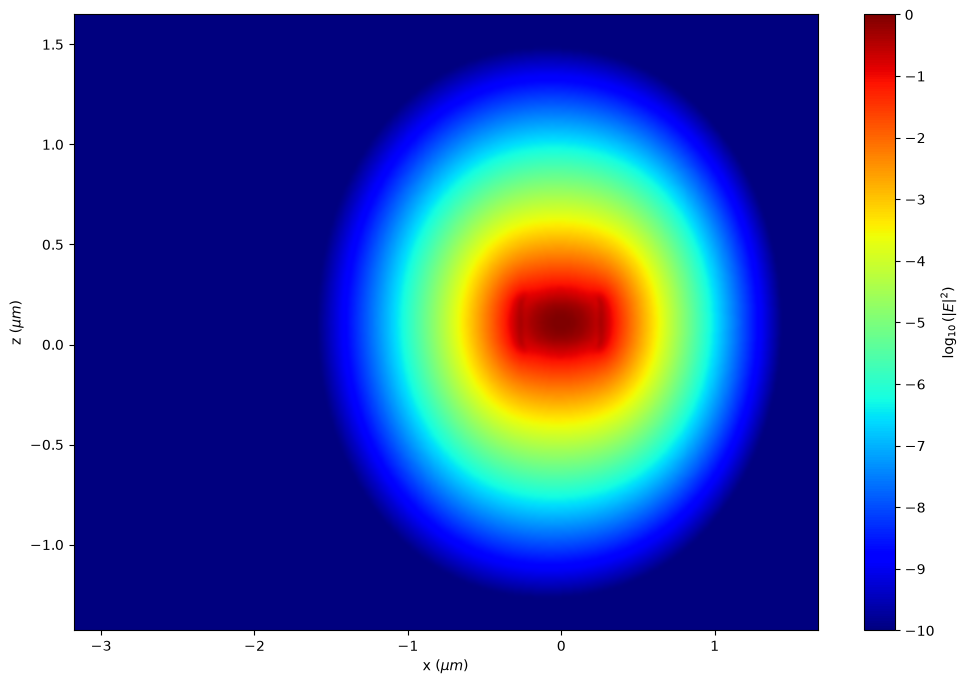

In [97]:
for Efield in [radius_data["Efield"][0], radius_data["Efield"][-1]]:
    fig, ax  = lu.plot_Efield(Efield)
    plt.show()